# 독일 신용 데이터 분류 분석 (German Credit Classification)

## 프로젝트
독일 신용 데이터(`german_credit_data.csv`)를 이용해 고객의 신용 위험(`Risk`)을 분류하는 머신러닝 실습

### 분석 목표
- 데이터의 구조와 분포를 파악
- 결측치와 범주형 데이터를 처리
- 여러 분류 알고리즘의 성능을 비교
- 교차검증과 그리드 탐색으로 모델의 하이퍼파라미터를 조정
- 테스트 데이터에서 최종 모델의 성능을 평가


## 1. 라이브러리 불러오기



In [ ]:
# 데이터 처리와 수치 계산
import os
import warnings
import numpy as np
import pandas as pd

# 데이터 시각화
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix

# 데이터 분리와 교차검증
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

# 결측치 처리와 범주형 변수 인코딩
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 분류 알고리즘
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier
)

# 모델 평가 지표
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 경고 메시지와 화면 출력 설정
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
pd.set_option("display.precision", 3)

sns.set_theme(style="whitegrid")

## 2. 데이터 불러오기



In [ ]:
# 데이터 파일이 현재 폴더에 있는지 확인
data_path = "german_credit_data.csv"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        "german_credit_data.csv 파일을 노트북과 같은 폴더에 저장해 주세요."
    )

# CSV 파일 읽기
dataset = pd.read_csv(data_path)

print("데이터 크기:", dataset.shape)
display(dataset.head())

데이터 크기: (1000, 10)


,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## 3. 탐색적 데이터 분석(EDA)

### 3.1 데이터 구조와 컬럼명 확인

In [ ]:
# 컬럼명 앞뒤 공백 제거
dataset.columns = dataset.columns.astype(str).str.strip()

# 데이터셋에서 자주 나타나는 컬럼명 표기를 표준 이름으로 변경
column_aliases = {
    "Saving accounts": "SavingAccounts",
    "Saving account": "SavingAccounts",
    "Checking account": "CheckingAccount",
    "Credit amount": "CreditAmount"
}
dataset = dataset.rename(columns=column_aliases)

print("컬럼 목록:")
print(dataset.columns.tolist())

print("\n데이터 정보:")
dataset.info()

# 예측 대상 컬럼이 있는지 확인
if "Risk" not in dataset.columns:
    raise KeyError(
        "'Risk' 컬럼을 찾을 수 없습니다. 실제 컬럼명을 확인해 주세요."
    )

컬럼 목록:
['Age', 'Sex', 'Job', 'Housing', 'SavingAccounts', 'CheckingAccount', 'CreditAmount', 'Duration', 'Purpose', 'Risk']

데이터 정보:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              1000 non-null   int64
 1   Sex              1000 non-null   str  
 2   Job              1000 non-null   int64
 3   Housing          1000 non-null   str  
 4   SavingAccounts   817 non-null    str  
 5   CheckingAccount  606 non-null    str  
 6   CreditAmount     1000 non-null   int64
 7   Duration         1000 non-null   int64
 8   Purpose          1000 non-null   str  
 9   Risk             1000 non-null   str  
dtypes: int64(4), str(6)
memory usage: 107.3 KB


### 3.2 기술통계량


In [ ]:
# 전체 컬럼의 기술통계량 확인
display(dataset.describe(include="all").T)

# 데이터 행과 열의 개수 확인
print("행 개수:", dataset.shape[0])
print("열 개수:", dataset.shape[1])

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1000.0,NaN,NaN,NaN,35.546,11.375,19.0,27.0,33.0,42.0,75.0
Sex,1000,2,male,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job,1000.0,NaN,NaN,NaN,1.904,0.654,0.0,2.0,2.0,2.0,3.0
Housing,1000,3,own,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SavingAccounts,817,4,little,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CheckingAccount,606,3,little,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditAmount,1000.0,NaN,NaN,NaN,3271.258,2822.737,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,NaN,NaN,NaN,20.903,12.059,4.0,12.0,18.0,24.0,72.0
Purpose,1000,8,car,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Risk,1000,2,good,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN


행 개수: 1000
열 개수: 10


### 3.3 클래스 분포 확인


Risk
good    700
bad     300
Name: count, dtype: int64

클래스별 비율(%):
Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64


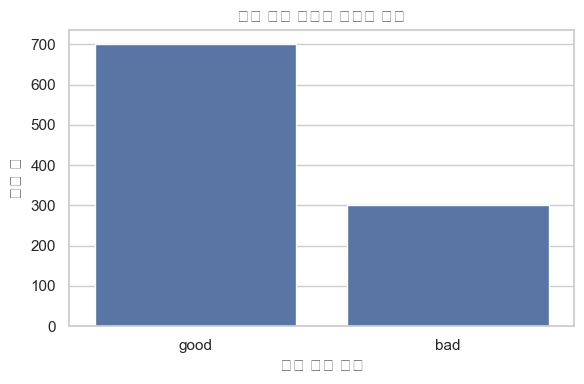

In [ ]:
# 신용 위험 등급별 데이터 건수
print(dataset["Risk"].value_counts(dropna=False))

# 신용 위험 등급별 비율(%)
risk_ratio = dataset["Risk"].value_counts(normalize=True, dropna=False) * 100
print("\n클래스별 비율(%):")
print(risk_ratio.round(2))

# 클래스 분포 시각화
plt.figure(figsize=(6, 4))
sns.countplot(data=dataset, x="Risk", order=dataset["Risk"].value_counts().index)
plt.title("신용 위험 등급별 데이터 분포")
plt.xlabel("신용 위험 등급")
plt.ylabel("고객 수")
plt.tight_layout()
plt.show()

### 3.4 데이터 분포 시각화



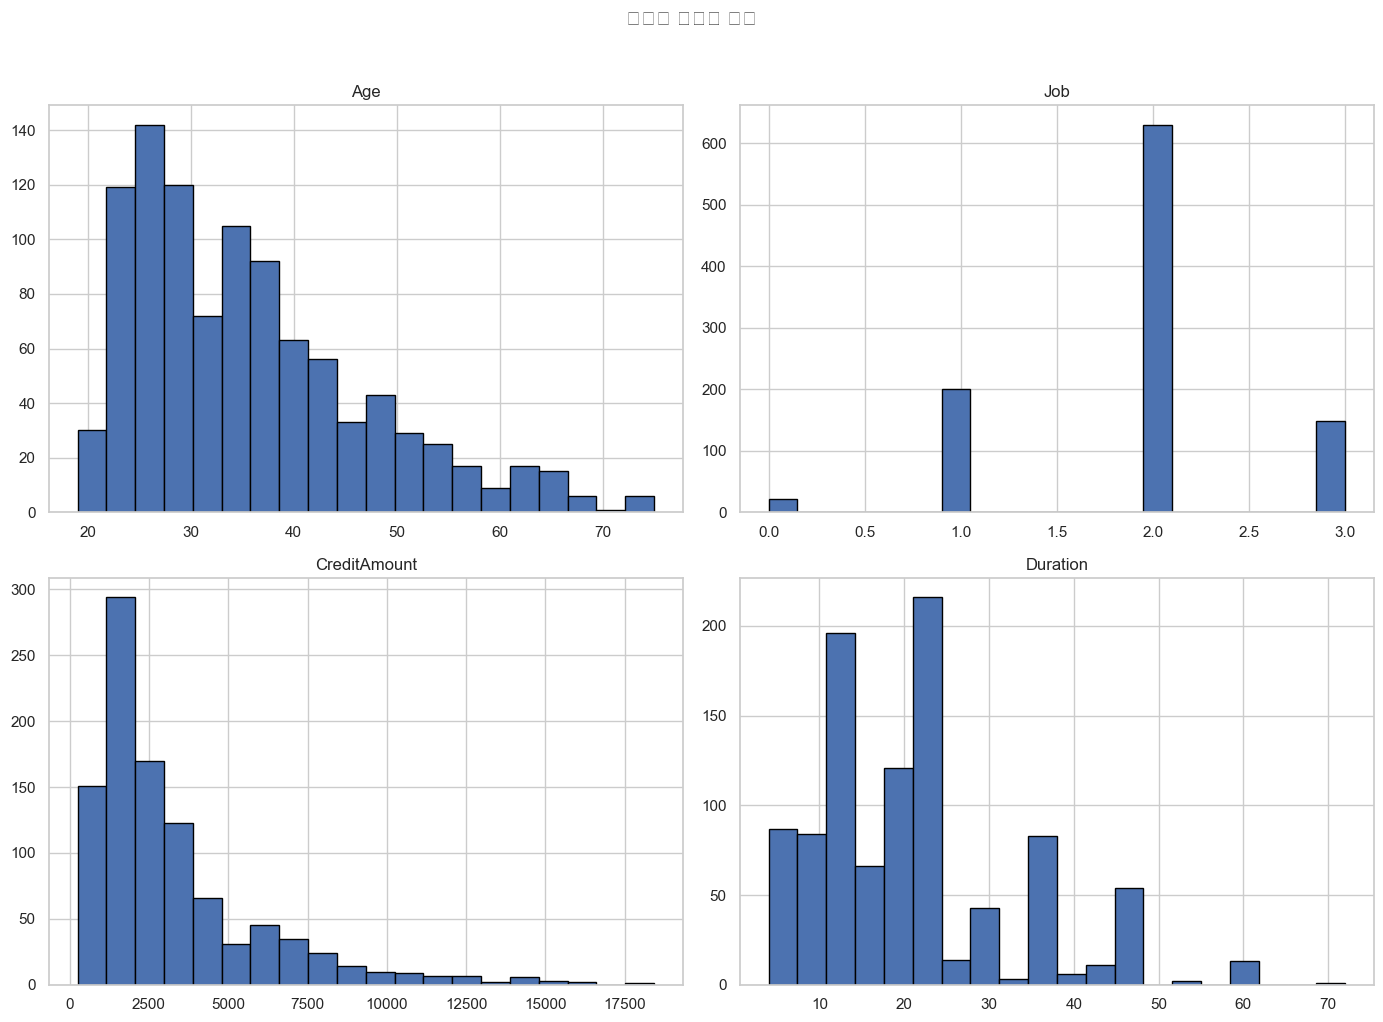

In [ ]:
# 숫자형 컬럼만 선택
numeric_columns = dataset.select_dtypes(include=np.number).columns.tolist()

if numeric_columns:
    dataset[numeric_columns].hist(
        figsize=(14, 10),
        bins=20,
        edgecolor="black"
    )
    plt.suptitle("숫자형 변수의 분포", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("시각화할 숫자형 컬럼이 없습니다.")

### 3.5 상자그림으로 이상치 탐색



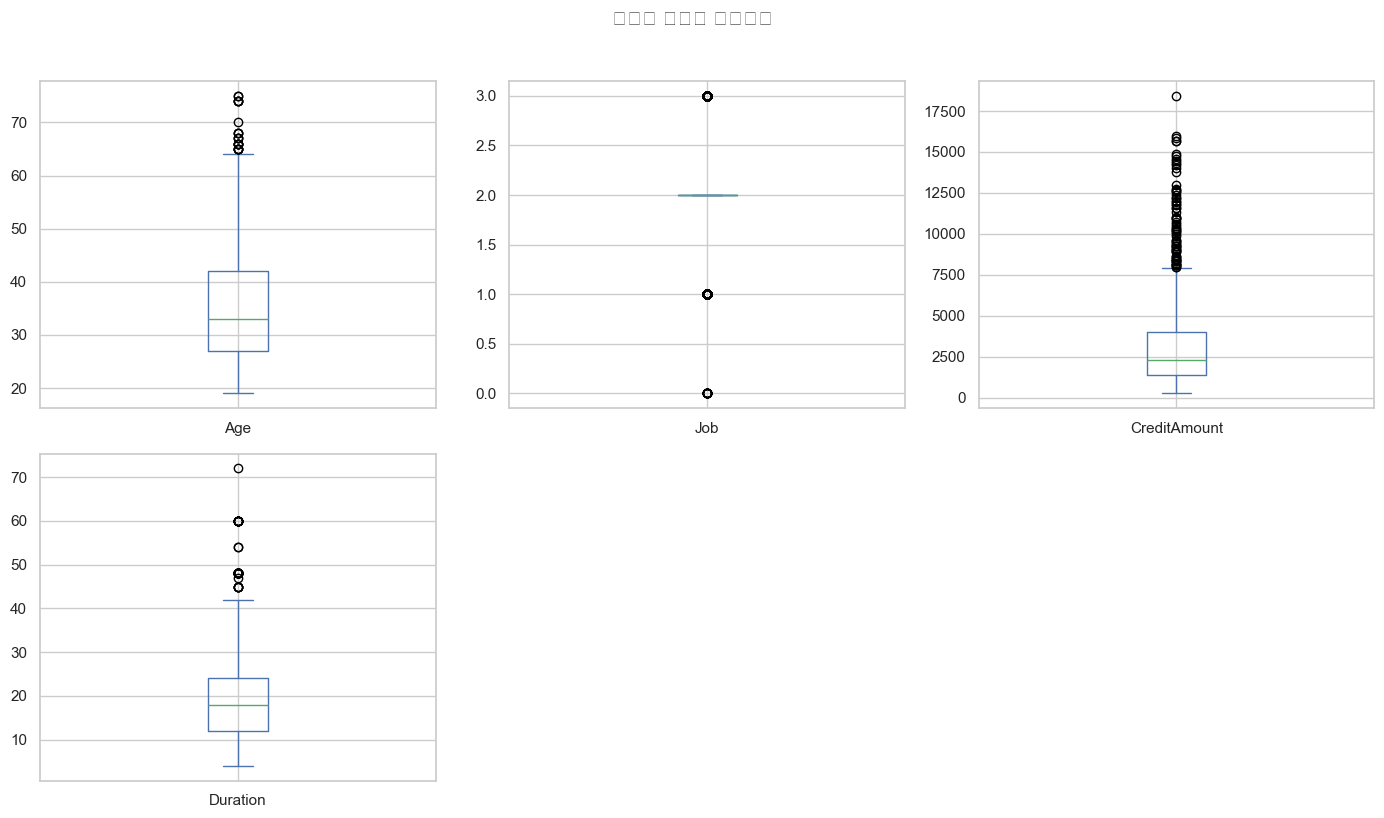

In [ ]:
if numeric_columns:
    dataset[numeric_columns].plot(
        kind="box",
        subplots=True,
        layout=(max(1, (len(numeric_columns) + 2) // 3), 3),
        figsize=(14, 4 * max(1, (len(numeric_columns) + 2) // 3)),
        sharex=False,
        sharey=False
    )
    plt.suptitle("숫자형 변수의 상자그림", y=1.02)
    plt.tight_layout()
    plt.show()

### 3.6 상관관계 분석



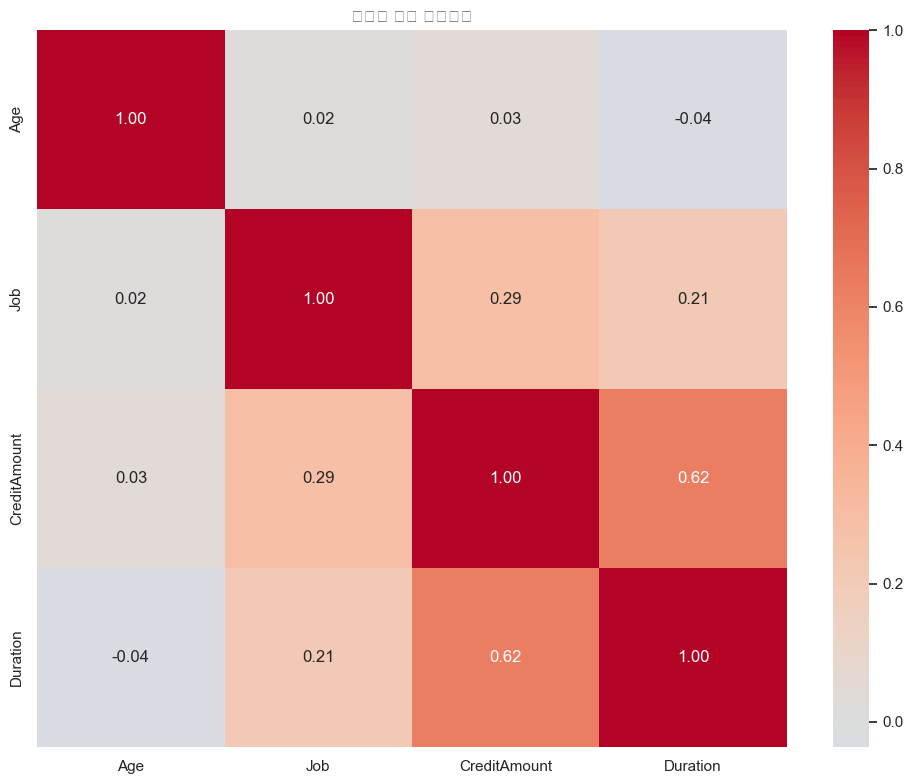

In [ ]:
correlation = dataset.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("숫자형 변수 상관관계")
plt.tight_layout()
plt.show()

## 4. 데이터 전처리

### 4.1 결측치 확인



In [ ]:
# 컬럼별 결측치 개수와 비율
missing_summary = pd.DataFrame({
    "결측치 개수": dataset.isnull().sum(),
    "결측치 비율(%)": dataset.isnull().mean() * 100
})

display(missing_summary.sort_values("결측치 개수", ascending=False))

,결측치 개수,결측치 비율(%)
CheckingAccount,394,39.4
SavingAccounts,183,18.3
Sex,0,0.0
Age,0,0.0
Housing,0,0.0
Job,0,0.0
CreditAmount,0,0.0
Duration,0,0.0
Purpose,0,0.0
Risk,0,0.0


### 4.2 입력 변수와 정답 변수 분리



In [ ]:
# 정답 변수에 결측치가 있는 행 제거
dataset = dataset.dropna(subset=["Risk"]).copy()

# 입력 변수와 정답 변수 분리
X = dataset.drop(columns=["Risk"])
y_text = dataset["Risk"].astype(str).str.strip()

# 일반적인 German Credit 데이터의 good/bad 표기를 0/1로 변환
risk_lower = y_text.str.lower()
if set(risk_lower.unique()).issubset({"good", "bad"}):
    y = risk_lower.map({"good": 0, "bad": 1}).astype(int)
    print("정답 인코딩: good=0, bad=1")
else:
    # 다른 클래스 표기인 경우 클래스 이름을 정수로 변환
    from sklearn.preprocessing import LabelEncoder
    target_encoder = LabelEncoder()
    y = pd.Series(
        target_encoder.fit_transform(y_text),
        index=y_text.index,
        name="Risk"
    )
    print("정답 클래스 인코딩:", dict(zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))))

print("입력 변수 크기:", X.shape)
print("정답 변수 분포:")
print(y.value_counts())

정답 인코딩: good=0, bad=1
입력 변수 크기: (1000, 9)
정답 변수 분포:
Risk
0    700
1    300
Name: count, dtype: int64


### 4.3 학습 데이터와 테스트 데이터 분리



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7,
    stratify=y
)

print("학습 데이터 크기:", X_train.shape)
print("테스트 데이터 크기:", X_test.shape)

print("\n학습 데이터 클래스 비율:")
print(y_train.value_counts(normalize=True).round(3))

print("\n테스트 데이터 클래스 비율:")
print(y_test.value_counts(normalize=True).round(3))

학습 데이터 크기: (800, 9)
테스트 데이터 크기: (200, 9)

학습 데이터 클래스 비율:
Risk
0    0.7
1    0.3
Name: proportion, dtype: float64

테스트 데이터 클래스 비율:
Risk
0    0.7
1    0.3
Name: proportion, dtype: float64


### 4.4 숫자형·범주형 변수 구분 및 전처리 파이프라인



In [ ]:
# 학습 데이터 기준으로 숫자형과 범주형 컬럼 구분
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("숫자형 변수:", numeric_features)
print("범주형 변수:", categorical_features)

# 숫자형 변수 전처리: 결측치 중앙값 대체 + 표준화
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 범주형 변수 전처리: 결측치 최빈값 대체 + 원-핫 인코딩
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# 컬럼별 전처리 결합
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

숫자형 변수: ['Age', 'Job', 'CreditAmount', 'Duration']
범주형 변수: ['Sex', 'Housing', 'SavingAccounts', 'CheckingAccount', 'Purpose']


## 5. 분류 알고리즘 비교

### 5.1 교차검증 설정



In [ ]:
# 교차검증 설정
num_folds = 5
seed = 7
scoring = "accuracy"

kfold = StratifiedKFold(
    n_splits=num_folds,
    shuffle=True,
    random_state=seed
)

### 5.2 기본 분류 모델 구성



In [ ]:
models = []

models.append(("LR", LogisticRegression(max_iter=2000)))
models.append(("LDA", LinearDiscriminantAnalysis()))
models.append(("KNN", KNeighborsClassifier()))
models.append(("CART", DecisionTreeClassifier(random_state=seed)))
models.append(("NB", GaussianNB()))
models.append(("SVM", SVC()))
models.append(("MLP", MLPClassifier(max_iter=1000, random_state=seed)))

# 앙상블 모델 추가
models.append(("AB", AdaBoostClassifier(random_state=seed)))
models.append(("GBM", GradientBoostingClassifier(random_state=seed)))
models.append(("RF", RandomForestClassifier(n_estimators=200, random_state=seed)))
models.append(("ET", ExtraTreesClassifier(n_estimators=200, random_state=seed)))

print("비교할 모델 수:", len(models))

비교할 모델 수: 11


### 5.3 모델별 교차검증 성능 비교



In [ ]:
results = []
names = []
model_pipelines = {}

for name, estimator in models:
    # 전처리와 분류기를 하나의 파이프라인으로 구성
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])

    # 층화 교차검증으로 성능 평가
    cv_results = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=kfold,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    results.append(cv_results)
    names.append(name)
    model_pipelines[name] = model_pipeline

    print(
        f"{name}: 평균 {cv_results.mean():.4f}, "
        f"표준편차 {cv_results.std():.4f}"
    )

LR: 평균 0.7000, 표준편차 0.0194
LDA: 평균 0.7000, 표준편차 0.0217
KNN: 평균 0.6687, 표준편차 0.0230
CART: 평균 0.6038, 표준편차 0.0355
NB: 평균 0.6175, 표준편차 0.0228
SVM: 평균 0.7000, 표준편차 0.0143
MLP: 평균 0.6537, 표준편차 0.0355
AB: 평균 0.6850, 표준편차 0.0281
GBM: 평균 0.6800, 표준편차 0.0341
RF: 평균 0.6875, 표준편차 0.0285
ET: 평균 0.6588, 표준편차 0.0276


### 5.4 모델 성능 시각화



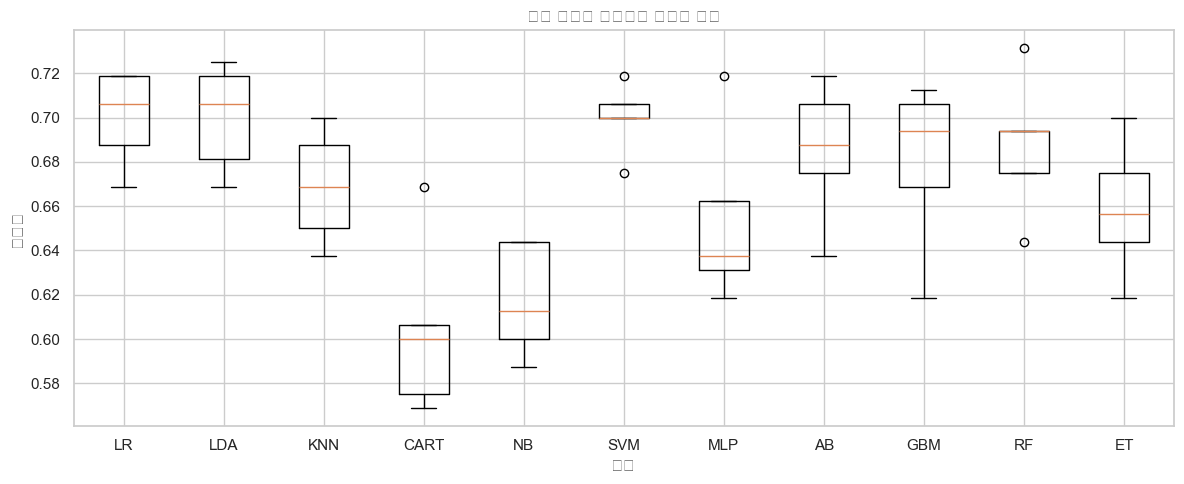

In [ ]:
plt.figure(figsize=(12, 5))
plt.boxplot(results, tick_labels=names)
plt.title("분류 모델별 교차검증 정확도 비교")
plt.xlabel("모델")
plt.ylabel("정확도")
plt.tight_layout()
plt.show()

## 6. 하이퍼파라미터 튜닝

### 6.1 그리드 탐색이란?



In [ ]:
# 모델별 탐색 대상 하이퍼파라미터
param_grids = {
    "LR": {
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"]
    },
    "CART": {
        "classifier__max_depth": [2, 3, 5, 7, 10, None],
        "classifier__min_samples_split": [2, 5, 10]
    },
    "RF": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 5, 10],
        "classifier__min_samples_split": [2, 5]
    }
}

### 6.2 로지스틱 회귀 하이퍼파라미터 탐색



In [ ]:
lr_search = GridSearchCV(
    estimator=model_pipelines["LR"],
    param_grid=param_grids["LR"],
    scoring=scoring,
    cv=kfold,
    n_jobs=-1
)

lr_search.fit(X_train, y_train)

print("최고 교차검증 점수:", round(lr_search.best_score_, 4))
print("최적 하이퍼파라미터:", lr_search.best_params_)

최고 교차검증 점수: 0.7013
최적 하이퍼파라미터: {'classifier__C': 0.1}


### 6.3 KNN 하이퍼파라미터 탐색



In [ ]:
knn_search = GridSearchCV(
    estimator=model_pipelines["KNN"],
    param_grid=param_grids["KNN"],
    scoring=scoring,
    cv=kfold,
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

print("최고 교차검증 점수:", round(knn_search.best_score_, 4))
print("최적 하이퍼파라미터:", knn_search.best_params_)

최고 교차검증 점수: 0.6862
최적 하이퍼파라미터: {'classifier__n_neighbors': 11, 'classifier__weights': 'uniform'}


### 6.4 의사결정나무 하이퍼파라미터 탐색



In [ ]:
cart_search = GridSearchCV(
    estimator=model_pipelines["CART"],
    param_grid=param_grids["CART"],
    scoring=scoring,
    cv=kfold,
    n_jobs=-1
)

cart_search.fit(X_train, y_train)

print("최고 교차검증 점수:", round(cart_search.best_score_, 4))
print("최적 하이퍼파라미터:", cart_search.best_params_)

최고 교차검증 점수: 0.6825
최적 하이퍼파라미터: {'classifier__max_depth': 2, 'classifier__min_samples_split': 2}


### 6.5 랜덤 포레스트 하이퍼파라미터 탐색



In [ ]:
rf_search = GridSearchCV(
    estimator=model_pipelines["RF"],
    param_grid=param_grids["RF"],
    scoring=scoring,
    cv=kfold,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("최고 교차검증 점수:", round(rf_search.best_score_, 4))
print("최적 하이퍼파라미터:", rf_search.best_params_)

최고 교차검증 점수: 0.7012
최적 하이퍼파라미터: {'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}


### 6.6 하이퍼파라미터 탐색 결과 비교



In [ ]:
tuning_results = pd.DataFrame([
    {"모델": "로지스틱 회귀", "최고 교차검증 정확도": lr_search.best_score_, "최적 설정": lr_search.best_params_},
    {"모델": "KNN", "최고 교차검증 정확도": knn_search.best_score_, "최적 설정": knn_search.best_params_},
    {"모델": "의사결정나무", "최고 교차검증 정확도": cart_search.best_score_, "최적 설정": cart_search.best_params_},
    {"모델": "랜덤 포레스트", "최고 교차검증 정확도": rf_search.best_score_, "최적 설정": rf_search.best_params_}
])

display(tuning_results.sort_values("최고 교차검증 정확도", ascending=False))

,모델,최고 교차검증 정확도,최적 설정
0,로지스틱 회귀,0.701,{'classifier__C': 0.1}
3,랜덤 포레스트,0.701,"{'classifier__max_depth': 5, 'classifier__min_..."
1,KNN,0.686,"{'classifier__n_neighbors': 11, 'classifier__w..."
2,의사결정나무,0.682,"{'classifier__max_depth': 2, 'classifier__min_..."


## 7. 최종 모델 평가

### 7.1 최적 모델 선택



In [ ]:
searches = {
    "로지스틱 회귀": lr_search,
    "KNN": knn_search,
    "의사결정나무": cart_search,
    "랜덤 포레스트": rf_search
}

best_name = max(searches, key=lambda name: searches[name].best_score_)
best_search = searches[best_name]
best_model = best_search.best_estimator_

print("선택된 모델:", best_name)
print("교차검증 최고 정확도:", round(best_search.best_score_, 4))
print("최적 하이퍼파라미터:", best_search.best_params_)

선택된 모델: 로지스틱 회귀
교차검증 최고 정확도: 0.7013
최적 하이퍼파라미터: {'classifier__C': 0.1}


### 7.2 테스트 데이터 예측 및 평가



In [ ]:
# 테스트 데이터 예측
y_pred = best_model.predict(X_test)

# 주요 평가 지표 계산
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"정확도(Accuracy): {accuracy:.4f}")
print(f"정밀도(Precision): {precision:.4f}")
print(f"재현율(Recall): {recall:.4f}")
print(f"F1 점수(F1-score): {f1:.4f}")

print("\n분류 성능 보고서:")
print(classification_report(y_test, y_pred, zero_division=0))

정확도(Accuracy): 0.7300
정밀도(Precision): 0.6875
재현율(Recall): 0.1833
F1 점수(F1-score): 0.2895

분류 성능 보고서:
              precision    recall  f1-score   support

           0       0.73      0.96      0.83       140
           1       0.69      0.18      0.29        60

    accuracy                           0.73       200
   macro avg       0.71      0.57      0.56       200
weighted avg       0.72      0.73      0.67       200



### 7.3 혼동행렬 시각화



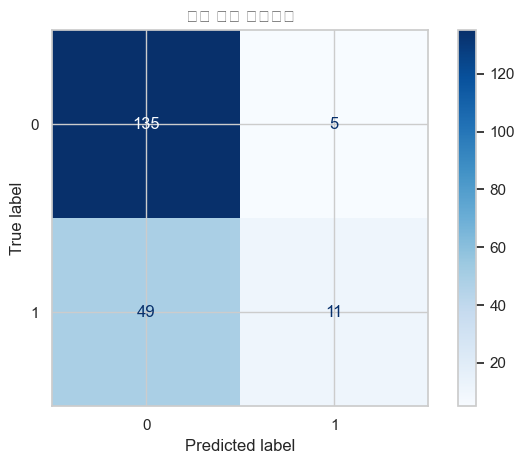

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d"
)
plt.title("최종 모델 혼동행렬")
plt.tight_layout()
plt.show()

## 8. 모델 저장 및 불러오기


In [ ]:
import joblib

# 전처리와 분류기를 포함한 최종 모델 저장
model_path = "german_credit_best_model.joblib"
joblib.dump(best_model, model_path)

print("모델 저장 완료:", model_path)

모델 저장 완료: german_credit_best_model.joblib


In [ ]:
# 저장된 모델 불러오기
loaded_model = joblib.load("german_credit_best_model.joblib")

# 테스트 데이터로 다시 예측
loaded_predictions = loaded_model.predict(X_test)

print(
    "불러온 모델의 테스트 정확도:",
    round(accuracy_score(y_test, loaded_predictions), 4)
)

불러온 모델의 테스트 정확도: 0.73
